## Model Evaluation – Credit Card Fraud Detection

### Installing and importing the libraries

In [3]:
!pip install imbalanced-learn


   ---------------------------------------- 0/2 [sklearn-compat]
   ---------------------------------------- 0/2 [sklearn-compat]
   ---------------------------------------- 0/2 [sklearn-compat]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]


In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, precision_score, recall_score,
                             f1_score, roc_auc_score, precision_recall_curve, auc, accuracy_score)
from imblearn.pipeline import Pipeline as ImbPipeline   # note: use imbalanced-learn's pipeline
from imblearn.over_sampling import SMOTE
import warnings
warnings.filterwarnings('ignore')

###  Load data and quick prep

In [5]:
df = pd.read_csv('creditcard.csv')
print("Class distribution:\n", df['Class'].value_counts())
print("Fraud percentage: {:.4f}%".format(100 * df['Class'].mean()))

Class distribution:
 Class
0    284315
1       492
Name: count, dtype: int64
Fraud percentage: 0.1727%


### Features V1..V28 + 'Amount', target 'Class'

In [6]:
X = df.drop(columns=['Class', 'Time'], errors='ignore')
y = df['Class']

### Train / test split (maintain class proportion)

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

### Pipeline with SMOTE + logistic regression

In [8]:
pipeline = ImbPipeline(steps=[
    ('scaler', StandardScaler()),               # fraud data often needs scaling
    ('smote', SMOTE(sampling_strategy=0.5, random_state=42)),  # oversample minority to 50% of majority
    ('clf', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))
])


### Fit on training data

In [9]:
pipeline.fit(X_train, y_train)

,steps,"[('scaler', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](2,)","[0,1]"
feature_names_in_,"ndarray[object](29,)","['V1','V2','V3',...,'V27','V28','Amount']"
n_features_in_,int,29
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


### Cross‑validated predictions for robust evaluation

#### We'll use 3-fold stratified CV to generate predictions across all training data

In [10]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
y_train_pred = cross_val_predict(pipeline, X_train, y_train, cv=cv, method='predict')
y_train_proba = cross_val_predict(pipeline, X_train, y_train, cv=cv, method='predict_proba')[:,1]

### Key evaluation metrics (on training CV)

In [13]:
print("\n--- Training Set CV Evaluation ---")
print("Accuracy: {:.4f} (misleading)".format(accuracy_score(y_train, y_train_pred)))
print("Precision: {:.4f}".format(precision_score(y_train, y_train_pred)))
print("Recall: {:.4f}".format(recall_score(y_train, y_train_pred)))
print("F1-score: {:.4f}".format(f1_score(y_train, y_train_pred)))
print("ROC AUC: {:.4f}".format(roc_auc_score(y_train, y_train_proba)))



--- Training Set CV Evaluation ---
Accuracy: 0.9735 (misleading)
Precision: 0.0561
Recall: 0.9036
F1-score: 0.1056
ROC AUC: 0.9737


### Confusion Matrix

FileNotFoundError: [Errno 2] No such file or directory: 'visuals/fraud_confusion_matrix.png'

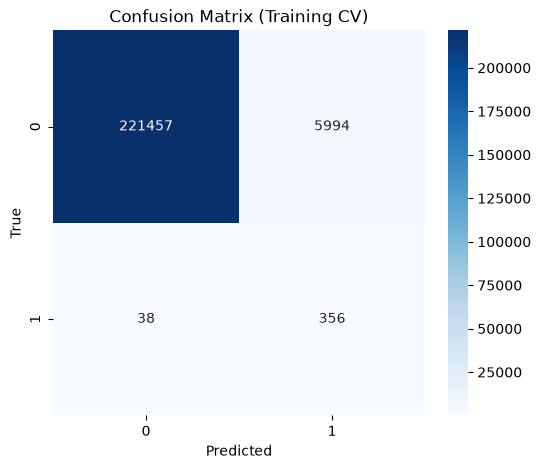

In [14]:
cm = confusion_matrix(y_train, y_train_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix (Training CV)')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.savefig('visuals/fraud_confusion_matrix.png', dpi=150)
plt.close()

### Precision‑Recall curve

FileNotFoundError: [Errno 2] No such file or directory: 'visuals/fraud_pr_curve.png'

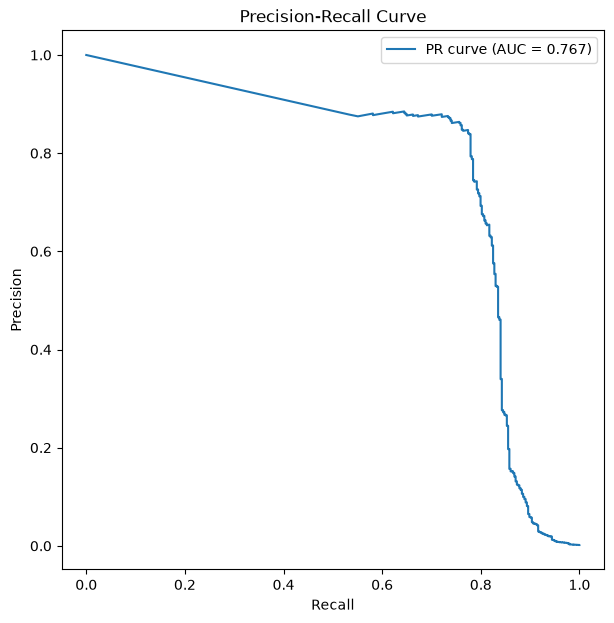

In [15]:
precisions, recalls, thresholds = precision_recall_curve(y_train, y_train_proba)
pr_auc = auc(recalls, precisions)
plt.figure(figsize=(7,7))
plt.plot(recalls, precisions, label=f'PR curve (AUC = {pr_auc:.3f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision‑Recall Curve')
plt.legend()
plt.savefig('visuals/fraud_pr_curve.png', dpi=150)
plt.close()

### Evaluation on unseen test set

In [16]:
y_test_pred = pipeline.predict(X_test)
y_test_proba = pipeline.predict_proba(X_test)[:,1]

print("\n--- Unseen Test Set Evaluation ---")
print("F1-score: {:.4f}".format(f1_score(y_test, y_test_pred)))
print("ROC AUC: {:.4f}".format(roc_auc_score(y_test, y_test_proba)))




--- Unseen Test Set Evaluation ---
F1-score: 0.1058
ROC AUC: 0.9700


### Plot test confusion matrix

FileNotFoundError: [Errno 2] No such file or directory: 'visuals/fraud_test_confusion.png'

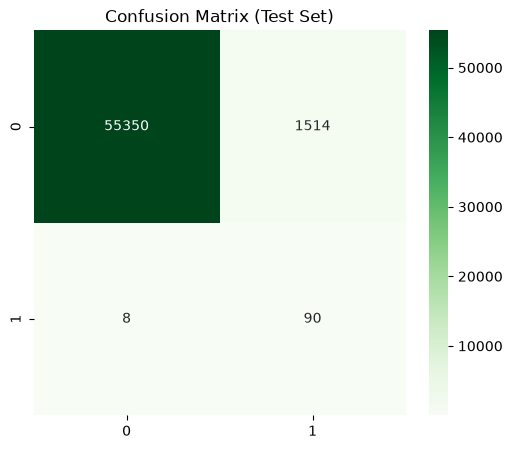

In [17]:
cm_test = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm_test, annot=True, fmt='d', cmap='Greens')
plt.title('Confusion Matrix (Test Set)')
plt.savefig('visuals/fraud_test_confusion.png', dpi=150)
plt.close()